In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords

In [3]:
data = pd.read_csv("Movie_Review.csv")

In [4]:
data.dropna(inplace = True)

In [5]:
data

,text,sentiment
0,"My daughter liked it but I was aghast, that a ...",neg
1,I... No words. No words can describe this. I w...,neg
2,this film is basically a poor take on the old ...,neg
3,"This is a terrible movie, and I'm not even sur...",neg
4,First of all this movie is a piece of reality ...,pos
...,...,...
995,"""Campfire Tales"" is basically made up of three...",pos
996,I just saw this film at the phoenix film festi...,pos
997,It's out of question that the real Anna Anders...,pos
998,Michelle Pfeiffer stars as a mob widow who see...,pos


In [6]:
def clean_review(review):
    str = ' '.join(word for word in review.split() if word.lower() not in stopwords.words('english'))
    return str

In [7]:
data['text'] = data['text'].apply(clean_review)

In [8]:
#wordcloud
from wordcloud import WordCloud

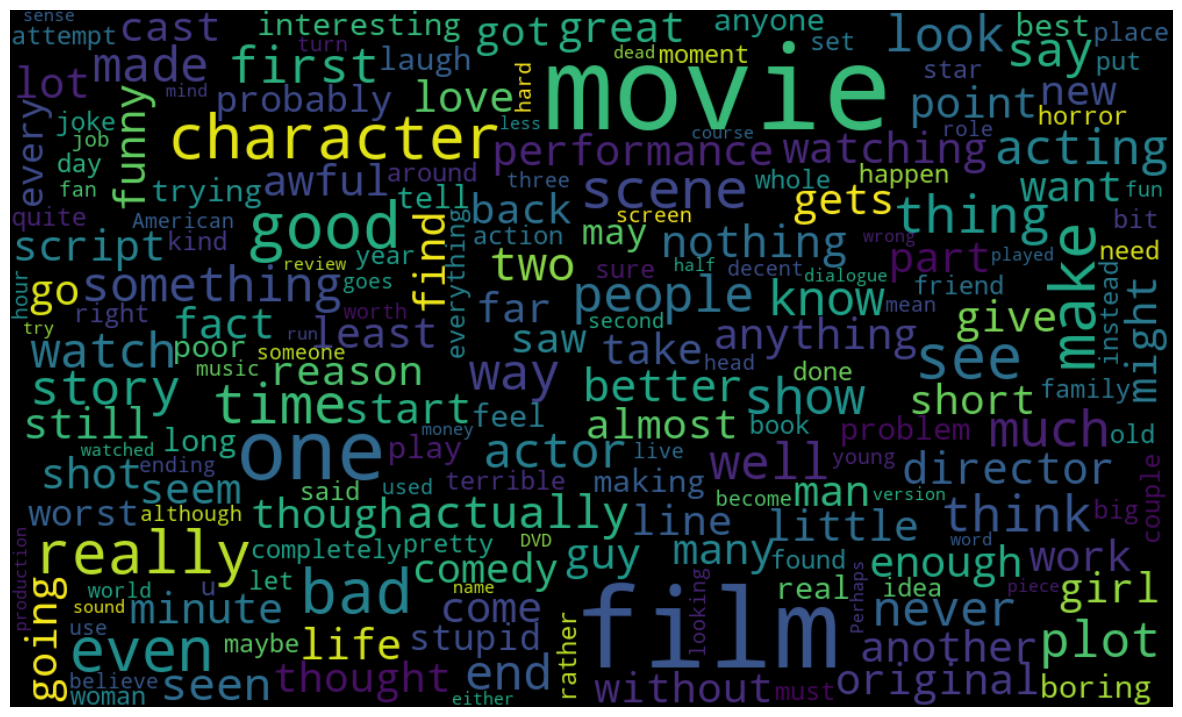

In [9]:
reviews = ' '.join(word for word in data['text'][data['sentiment'] == 'neg'].astype(str))
wordcloud = WordCloud(height = 600,width =1000, max_font_size = 100)
plt.figure(figsize = (15,12))
plt.imshow(wordcloud.generate(reviews), interpolation='bilinear')
plt.axis('off')
plt.show()

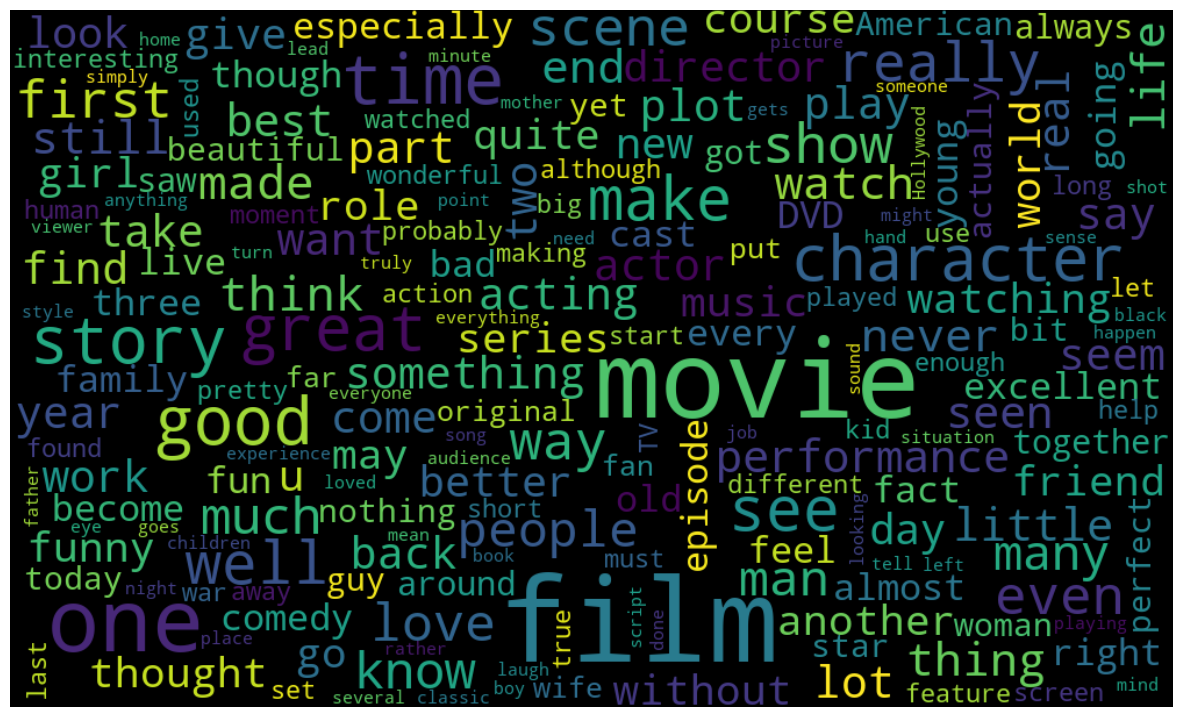

In [10]:
reviews = ' '.join(word for word in data['text'][data['sentiment'] == 'pos'].astype(str))
wordcloud = WordCloud(height = 600,width =1000, max_font_size = 100)
plt.figure(figsize = (15,12))
plt.imshow(wordcloud.generate(reviews), interpolation='bilinear')
plt.axis('off')
plt.show()

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
cv = TfidfVectorizer(max_features=2500)

In [12]:
reviews = cv.fit_transform(data['text']).toarray()

In [13]:
data['sentiment'] = data['sentiment'].replace(['pos','neg'],[1,0])

In [14]:
data['sentiment'].value_counts()

sentiment
0    500
1    500
Name: count, dtype: int64

In [15]:
from sklearn.linear_model import LogisticRegression

In [16]:
model = LogisticRegression()

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
reviews_train, reviews_test, sent_train, sent_test = train_test_split(reviews, data['sentiment'], test_size=0.2)

In [20]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
sent_train_encoded = le.fit_transform(sent_train)  # Converts strings to integers (0, 1, 2, etc.)

# Now fit the model with encoded labels
model.fit(reviews_train, sent_train_encoded)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [21]:
predict = model.predict(reviews_test)

Original size: 200
Clean size: 200
Model classes: [0 1]
Unique values in sent_test: [0 1]
Unique values in predict: [0 1]


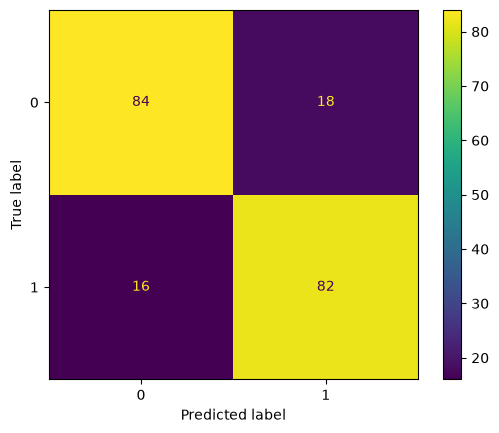

In [26]:
# Assistant
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import pandas as pd

# Check for and remove any NaN or None values
# Create a mask to identify valid (non-null) entries
valid_mask = ~(pd.isna(sent_test) | pd.isna(predict))

# Filter both arrays to keep only valid entries
sent_test_clean = np.array(sent_test)[valid_mask]
predict_clean = np.array(predict)[valid_mask]

# Convert to the same data type as model.classes_ to ensure consistency
# This prevents type mismatches between predictions and expected classes
sent_test_clean = sent_test_clean.astype(type(model.classes_[0]))
predict_clean = predict_clean.astype(type(model.classes_[0]))

# Filter out any values that are not in model.classes_
# This ensures only valid class labels are used in the confusion matrix
valid_classes_mask = np.isin(sent_test_clean, model.classes_) & np.isin(predict_clean, model.classes_)
sent_test_clean = sent_test_clean[valid_classes_mask]
predict_clean = predict_clean[valid_classes_mask]

# Optional: Print diagnostic information
print(f"Original size: {len(sent_test)}")
print(f"Clean size: {len(sent_test_clean)}")
print(f"Model classes: {model.classes_}")
print(f"Unique values in sent_test: {np.unique(sent_test_clean)}")
print(f"Unique values in predict: {np.unique(predict_clean)}")

# Create confusion matrix with cleaned data
cm = confusion_matrix(sent_test_clean, predict_clean, labels=model.classes_)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
display.plot()
plt.show()


**Key changes made:**
1. **Added data type conversion** to match `model.classes_` type
2. **Added filtering** using `np.isin()` to remove any values not in `model.classes_`
3. **Enhanced diagnostic output** to show model classes for better debugging

This ensures that only valid class labels recognized by your model are passed to the confusion matrix function.

In [27]:
import pickle as pk


In [29]:
pk.dump(model,open('model.pkl','wb'))

In [30]:
pk.dump(cv,open('scaler.pkl','wb'))